# BTX degradation by the isolates

**Question.** Do the isolates differ in how much **benzene (B)**, **toluene (T)** and **xylene (X)** they remove, and does any isolate remove more than the control `CN`?

**Design.** 11 groups (the control `CN` and 10 isolates) × 3 replicates. Every replicate was measured at the start (`t0`) and at the end (`tf`) of the assay, and the concentration of each compound is in mg/L.

| Variable | Levels | Taken from |
|---|---|---|
| `Isolate` | CN, SA1.3, SA1.4, SA2.1, SA2.6, SA2.7, SA3.3, SA3.4, SA3.5, SA3.7, SZ2.1 | text before the bracket in the `Sample` column |
| `Time` | t0, tf | text inside the bracket |
| `Rep` | 1, 2, 3 | `Rep` column |
| compound | B, T, X | concentration columns |

*Example: the cell `CN (t0)` = isolate **CN**, time **t0**.*

**Measure**

| Measure | Formula | Variables |
|---|---|---|
| `Δ` | `Δ = C(t0) − C(tf)` | `C` = concentration (mg/L) of the compound in the replicate. Positive `Δ` = the concentration **decreased**, 0 = no change, negative = it **increased** |

**Workflow**

1. Load libraries
2. Load the BTX concentrations
3. Degradation per replicate (`Δ = t0 − tf`)
4. Descriptive statistics by isolate
5. Differences among isolates: **Kruskal-Wallis** test
6. Post hoc: **Dunn** test against the control `CN` (toluene)
7. Figure (boxplots)
8. Reading the results

---
## 1. Setup

The packages used throughout this notebook are loaded below. All of them are available from CRAN.

CRAN:

install.packages(c("openxlsx", "dplyr", "tidyr", "dunn.test", "ggplot2"))

In [1]:
library(openxlsx)
library(dplyr)
library(tidyr)
library(dunn.test)
library(ggplot2)



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




---
## 2. Load the data

The `BTX` sheet of the Excel file holds one row per replicate and time (66 rows = 11 groups × 2 times × 3 replicates).

- The isolate and time are written only once per block of replicates (for example `CN (t0)`) and are left empty below it, so the empty cells are filled with the value above (`fill()`).
- `Sample` is then split into `Isolate` and `Time` at the opening bracket, and the closing bracket is removed from `Time`.
- The sample columns (2:3) and the concentration columns (11:13) are not next to each other in the sheet, so they are read separately and bound side by side.

In [2]:
btx_file <- "datasets/BTX_degradation.xlsx"

BTX <- cbind(read.xlsx(btx_file, sheet = "BTX", rows = 3:69, cols = 2:3),
             read.xlsx(btx_file, sheet = "BTX", rows = 3:69, cols = 11:13))

BTX <- BTX %>%
mutate(Sample = na_if(Sample, "")) %>%
fill(Sample) %>%
separate(Sample, into = c("Isolate", "Time"), sep = " \\(", extra = "merge") %>%
mutate(Time = sub("\\)", "", Time))

head(BTX)

,Isolate,Time,Rep,B,T,X
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,CN,t0,1,13.57856,18.15410,15.29501
2,CN,t0,2,15.80810,22.95030,16.03007
3,CN,t0,3,15.25477,16.22779,14.47635
4,CN,tf,1,14.63191,19.08921,14.57788
5,CN,tf,2,13.18986,17.81186,12.93086
6,CN,tf,3,13.48419,15.10053,12.37769


---
## 3. Degradation per replicate

For every replicate, we subtracted the concentration at the end of the assay from the concentration at the start: `Δ = t0 − tf`. A positive `Δ` means that the compound decreased.

- `pivot_wider()` puts `t0` and `tf` side by side (`B_t0`, `B_tf`, `T_t0`, ...), so that each replicate number is subtracted from itself.
- `transmute()` keeps `Isolate` and `Rep` and replaces the six concentration columns from `pivot_wider()` with the three differences, giving 11 isolates × 3 replicates = 33 rows.

In [3]:
BTX_diff <- BTX %>%
pivot_wider(names_from = Time, values_from = c(B, T, X)) %>%
transmute(Isolate, Rep,
          B = B_t0 - B_tf,
          T = T_t0 - T_tf,
          X = X_t0 - X_tf)

BTX_diff

Isolate,Rep,B,T,X
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
CN,1,-1.0533553,-0.93511702,0.7171369
CN,2,2.6182455,5.13843751,3.0992094
CN,3,1.7705866,1.12726084,2.0986636
SA3.5,1,5.4404477,3.70509627,2.6099885
SA3.5,2,2.2234135,4.86430719,4.1795903
SA3.5,3,3.7149398,5.08274799,4.4796641
SA2.1,1,1.0189670,1.62457031,3.3460579
SA2.1,2,-0.3678045,-0.94011385,0.4063860
SA2.1,3,1.3274582,1.59457584,0.9089888


---
## 4. Descriptive statistics by isolate

For each compound, the mean, median, minimum, maximum and standard deviation of `Δ` are calculated for every isolate (n = 3 per isolate).

- `group_by(Isolate)` splits the table by isolate and `across()` applies the five summary functions to the three compounds.

> With only 3 replicates per isolate, means and standard deviations are rough descriptions.

In [4]:
compounds <- c("B", "T", "X")

des_Isolate <- BTX_diff %>%
group_by(Isolate) %>%
summarise(
  across(
    all_of(compounds),
    list(
        Mean = ~mean(.x, na.rm = TRUE),
        Median = ~median(.x, na.rm = TRUE),
        Min = ~min(.x, na.rm = TRUE),
        Max = ~max(.x, na.rm = TRUE),
        SD = ~sd(.x, na.rm = TRUE))),
    .groups = "drop")

des_Isolate

Isolate,B_Mean,B_Median,B_Min,B_Max,B_SD,T_Mean,T_Median,T_Min,T_Max,T_SD,X_Mean,X_Median,X_Min,X_Max,X_SD
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CN,1.11182558,1.7705866,-1.0533553,2.618245,1.9224041,1.7768604,1.1272608,-0.93511702,5.138438,3.0884464,1.97166997,2.0986636,0.7171369,3.0992094,1.1961032
SA1.3,3.91238564,2.4727201,2.0067069,7.257730,2.9065080,2.6844440,2.8605544,2.11090001,3.081877,0.5088816,2.57960079,3.1204878,1.1789993,3.4393152,1.2233871
SA1.4,2.39153553,2.3373571,2.1693375,2.667912,0.2536644,3.3922763,3.3771003,3.26791930,3.531809,0.1325979,2.50382164,2.8514567,1.7353993,2.9246089,0.6664776
SA2.1,0.65954026,1.0189670,-0.3678045,1.327458,0.9029782,0.7596774,1.5945758,-0.94011385,1.624570,1.4721388,1.55381094,0.9089888,0.4063860,3.3460579,1.5723436
SA2.6,2.71168911,2.8295386,1.2121532,4.093376,1.4442219,5.5970498,5.1855851,3.68792063,7.917644,2.1446717,5.28223610,4.5952790,4.3417863,6.9096430,1.4150634
SA2.7,1.32434457,0.9515683,0.5443822,2.477083,1.0188498,1.7747992,1.5266851,0.50836917,3.289343,1.4069914,-0.06039899,0.6634396,-1.7674100,0.9227734,1.4839907
SA3.3,1.86412535,0.6090984,0.4339376,4.549340,2.3271128,1.2044353,0.4091230,-0.04801494,3.252198,1.7880834,2.16243874,1.7534159,1.3258016,3.4080987,1.0997568
SA3.4,0.25095743,-0.1888520,-0.2191447,1.160869,0.7881521,-0.1336671,-0.7513529,-1.47614609,1.826498,1.7358040,1.18576872,0.6730488,0.3920636,2.4921938,1.1400868
SA3.5,3.79293368,3.7149398,2.2234135,5.440448,1.6099347,4.5507171,4.8643072,3.70509627,5.082748,0.7404290,3.75641434,4.1795903,2.6099885,4.4796641,1.0041067


---
## 5. Differences among isolates: Kruskal-Wallis test

Do the 11 groups (`CN` + 10 isolates) differ in `Δ`? The test is run **separately for each compound**.

- `kruskal.test(compound ~ Isolate)` performs a Kruskal-Wallis rank-sum test. It is rank-based, so it does not assume normality, which suits 3 replicates per group. `Chi2` is the test statistic.
- `lapply()` repeats the test for each compound and `rbind()` stacks the results into one table (3 rows).
- The test only says that the groups differ somewhere, not which ones. That is what section 6 is for.

> **Limitation.** With 3 samples per group, the chi-squared approximation behind the *p*-value is rough and the test has little power, so read these *p*-values as indicative.

In [5]:
kw_results <- do.call(rbind, lapply(compounds, \(m) {
  test <- kruskal.test(as.formula(paste(m, "~ Isolate")), data = BTX_diff)
  data.frame(Compound = m, Chi2 = test$statistic, df = test$parameter, p = test$p.value)}))

print(kw_results, row.names = FALSE)

 Compound     Chi2 df          p
        B 14.84492 10 0.13781893
        T 20.06417 10 0.02865155
        X 17.83957 10 0.05773089


---
## 6. Post hoc: Dunn test against the control CN (toluene)

Which isolates differ from the control `CN`? This is run only for **toluene**, the only compound with a significant Kruskal-Wallis test in section 5 (xylene was borderline and benzene was not).

- `dunn.test()` compares every pair of groups using the ranks of all 33 values and returns `Z` and `P` for each pair.
- Only the 10 comparisons that involve `CN` are kept (`grepl("CN", Comparison)`). The Benjamini-Hochberg correction is then applied **to these 10 only**.
- The sign of `Z` gives the direction. In `CN - isolate`, a negative `Z` means that `CN` has the lower mean rank, i.e. the isolate removed **more** toluene than `CN`.

> **Note on `P`.** `dunn.test()` returns **two-sided** p-values (`altp = TRUE`).

> **Limitation.** With 3 samples per group, no single comparison has much power. Read the table as an exploration of how different each isolate is from `CN`.

In [6]:
res <- dunn.test(BTX_diff$T, BTX_diff$Isolate, method = "none", list = TRUE, kw = FALSE, altp = TRUE)

dunn_res <- data.frame(
  Comparison = res$comparisons,
  Z = res$Z,
  P = res$altP) %>%
filter(grepl("CN", Comparison)) %>%
mutate(p_adj = p.adjust(P, method = "BH")) %>%
arrange(p_adj)

dunn_res

                    Dunn's Pairwise Comparison of x by group                    
                                 (No adjustment)                                

Col Mean-│
Row Mean │         CN      SA1.3      SA1.4      SA2.1      SA2.6      SA2.7
─────────┼──────────────────────────────────────────────────────────────────
   SA1.3 │  -0.633300
         │     0.5265 
         │
   SA1.4 │  -1.266600  -0.633300
         │     0.2053     0.5265 
         │
   SA2.1 │   0.633300   1.266600   1.899901
         │     0.5265     0.2053     0.0574 
         │
   SA2.6 │  -2.026561  -1.393261  -0.759961  -2.659862
         │     0.0427*    0.1635     0.4473     0.0078*
         │
   SA2.7 │   0.000000   0.633300   1.266600  -0.633300   2.026561
         │     1.0000     0.5265     0.2053     0.5265     0.0427*
         │
   SA3.3 │   0.548860   1.182160   1.815461  -0.084440   2.575422   0.548860
         │     0.5831     0.2371     0.0695     0.9327     0.0100*    0.5831 
         │
   SA3

Comparison,Z,P,p_adj
<chr>,<dbl>,<dbl>,<dbl>
CN - SA2.6,-2.0265616,0.04270727,0.3472651
CN - SA3.5,-1.8154614,0.06945303,0.3472651
CN - SA1.4,-1.2666010,0.20529800,0.6843267
CN - SA1.3,-0.6333005,0.52653743,0.7288765
CN - SA2.1,0.6333005,0.52653743,0.7288765
CN - SA3.3,0.5488604,0.58310124,0.7288765
CN - SA3.4,0.8866207,0.37528315,0.7288765
CN - SZ2.1,0.6755205,0.49934511,0.7288765
CN - SA3.7,-0.2533202,0.80002079,0.8889120


---
## 7. Figure: concentration change by isolate

Boxplots of `Δ` for the three compounds in every group, with a dashed line at 0 (no change). Each box summarises only 3 values.

- Isolates are ordered with **`CN` first**, then by decreasing overall mean `Δ`. One very high replicate can therefore move an isolate to the left, as happens with SA3.7.


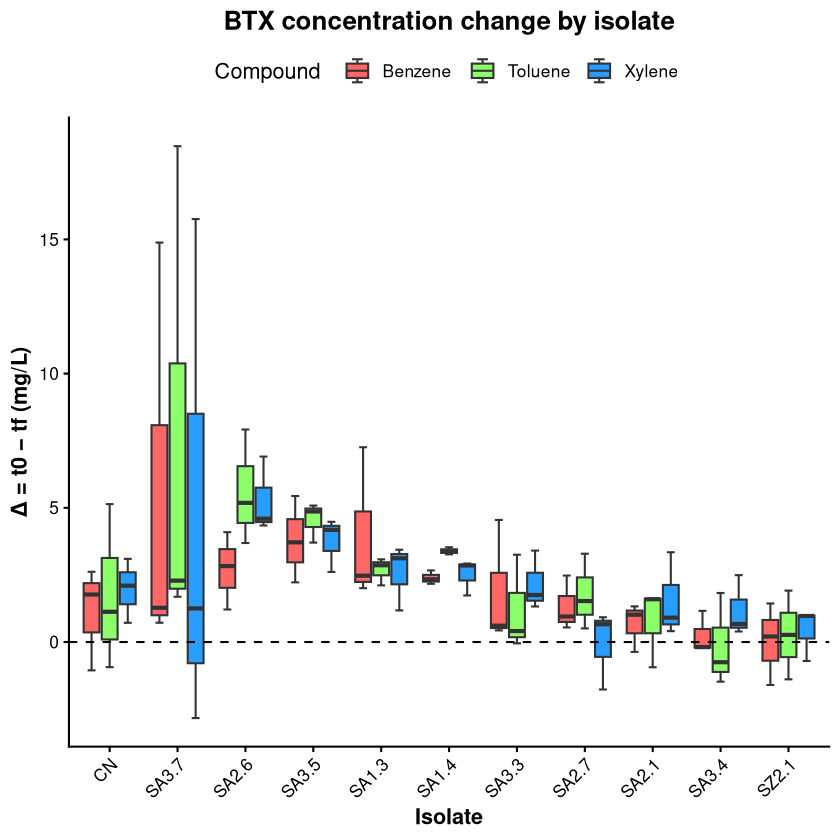

In [7]:
# Order isolates by mean
iso_order <- BTX_diff %>%
  group_by(Isolate) %>%
  summarise(Mean = mean(c(B, T, X), na.rm = TRUE), .groups = "drop") %>%
  filter(Isolate != "CN") %>%
  arrange(desc(Mean)) %>%
  pull(Isolate)

# Reshape for ggplot
BTX_long <- BTX_diff %>%
  pivot_longer(B:X, names_to = "Compound", values_to = "Delta") %>%
  mutate(Isolate = factor(Isolate, levels = c("CN", iso_order)))

# Plot
ggplot(BTX_long, aes(x = Isolate, y = Delta, fill = Compound)) +
  geom_boxplot(
    position = position_dodge(0.8),
    width = 0.7,
    alpha = 0.85,
    outlier.size = 1.8,
    staplewidth = 0.5) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "black") +
  scale_fill_manual(
    values = c(B = "#ff4b4b", T = "#79ff51", X = "#008cff"),
    labels = c(B = "Benzene", T = "Toluene", X = "Xylene")) +
  labs(
    title = "BTX concentration change by isolate",
    x = "Isolate",
    y = "Δ = t0 − tf (mg/L)",
    fill = "Compound") +
  theme_classic(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    axis.text.x = element_text(angle = 45, hjust = 1, colour = "black"),
    axis.title = element_text(face = "bold"),
    legend.position = "top")

---
## 8. Reading the results

**In short:** only toluene shows a significant difference among the isolates (Kruskal-Wallis *p* = 0.029). Xylene is borderline (*p* = 0.058) and benzene is not (*p* = 0.14). For toluene, no isolate differs significantly from the control `CN` after BH adjustment (smallest `p_adj` = 0.35), so the results are descriptive. SA2.6 and SA3.5 are the clearest candidates, and SA3.7 has the highest means only because of one replicate.

### Differences among isolates (11 groups, n = 33 per compound)

| Compound | `Chi2` (10 df) | *p* |
| --- | --- | --- |
| Benzene (B) | 14.85 | 0.138 |
| Toluene (T) | 20.06 | 0.029 |
| Xylene (X) | 17.84 | 0.058 |

* Only the toluene test is below 0.05. The three compounds were tested separately and with 3 replicates per isolate the chi-squared approximation is rough, so this is indicative rather than conclusive.
* The test only shows that the isolates differ somewhere, so the Dunn test below looks at toluene against `CN`.

### Isolates against the control CN (toluene)

| Isolate | Mean `Δ` (mg/L) | `Z` | `P` | `p_adj` (BH) |
| --- | --- | --- | --- | --- |
| SA2.6 | 5.60 | −2.03 | 0.043 | 0.35 |
| SA3.5 | 4.55 | −1.82 | 0.069 | 0.35 |
| SA1.4 | 3.39 | −1.27 | 0.21 | 0.68 |


* No isolate differs significantly from `CN`, even though the Kruskal-Wallis test was significant. The smallest `p_adj` is 0.35 (SA2.6 and SA3.5), and the other seven isolates have `p_adj` between 0.68 and 1.
* SA2.6 and SA3.5 are the two isolates with the lowest `P`, and their toluene means (5.60 and 4.55 mg/L) are the highest after SA3.7, whose mean is tilted by a single replicate, against 1.78 mg/L in `CN`. `CN` itself varies widely between replicates (−0.94 to 5.14 mg/L, SD 3.09), which makes a difference harder to detect with n = 3.


---
### References
* Dinno, A. (2026). dunn.test: Dunn’s Test of Multiple Comparisons Using Rank Sums. doi:10.32614/CRAN.package.dunn.test